## Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Evina Fitriyani | 5054251013 |

### Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

### Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

### Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

## 1. Persiapan Dataset dan Eksplorasi Awal

In [10]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score 



In [11]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.

df = pd.read_csv('Mall_Customers.csv')
df.head(5)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [13]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


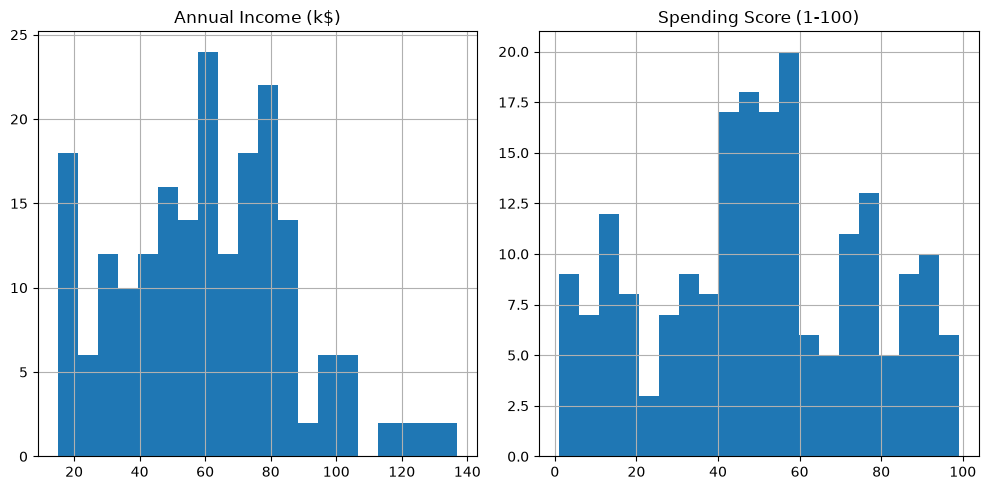

In [14]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
df[['Annual Income (k$)', 'Spending Score (1-100)']].hist(
    bins=20,
    figsize=(10, 5)
)
plt.tight_layout()
plt.show()


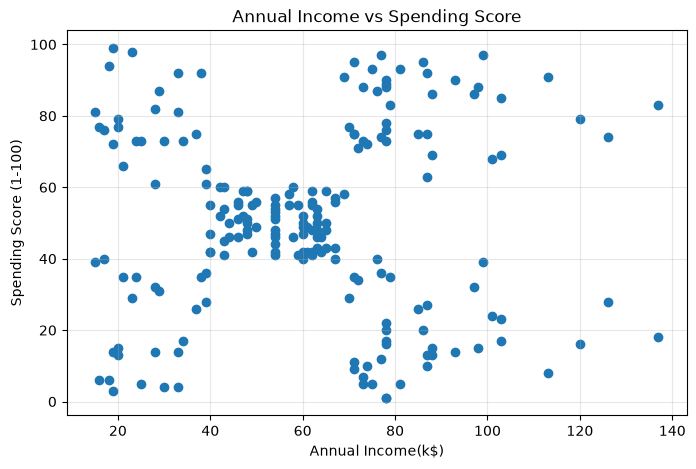

In [15]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(8, 5))
plt.scatter(df['Annual Income (k$)'], df['Spending Score (1-100)'])
plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income(k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, alpha=0.3)
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Jawaban:**

- Tidak ada missing value dan tidak ada baris duplikat. Semua kolom bernilai 0 di hasil `isnull().sum()`, dan `duplicated().sum()` juga 0.
- Annual Income berkisar 15 sampai 137 k$ (rata-rata 60.56, median 61.5). Distribusinya agak miring ke kanan, ada segelintir pelanggan di atas 100 k$ yang jaraknya cukup jauh dari mayoritas. Spending Score berkisar 1 sampai 99 (rata-rata 50.2, median 50) dengan sebaran yang lebih merata, puncaknya di sekitar 40 sampai 60.
- Di scatter plot, kelompoknya sudah kelihatan. Ada satu gerombol padat di tengah (income sekitar 40 sampai 70, spending sekitar 40 sampai 60), lalu empat kelompok lain di sudut-sudut plot. Jadi secara visual ada sekitar 5 kelompok yang terpisah.


In [16]:
# Melihat Missing Value 
print("Jumlah Missing Value:")
print(df.isnull().sum())

Jumlah Missing Value:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [17]:
# Melihat Baris Duplikat 
print("Jumlah baris Duplikat:")
print(df.duplicated().sum())

Jumlah baris Duplikat:
0


## 2. Preprocessing

In [18]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

df = df.drop_duplicates()
df = df.dropna()
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]
print(X.shape)
X.head()

(200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [19]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
print(X_scaled.head())
X_scaled.describe()

   Annual Income (k$)  Spending Score (1-100)
0           -1.738999               -0.434801
1           -1.738999                1.195704
2           -1.700830               -1.715913
3           -1.700830                1.040418
4           -1.662660               -0.395980


,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02
mean,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00
min,-1.738999e+00,-1.910021e+00
25%,-7.275093e-01,-5.997931e-01
50%,3.587926e-02,-7.764312e-03
75%,6.656748e-01,8.851316e-01
max,2.917671e+00,1.894492e+00


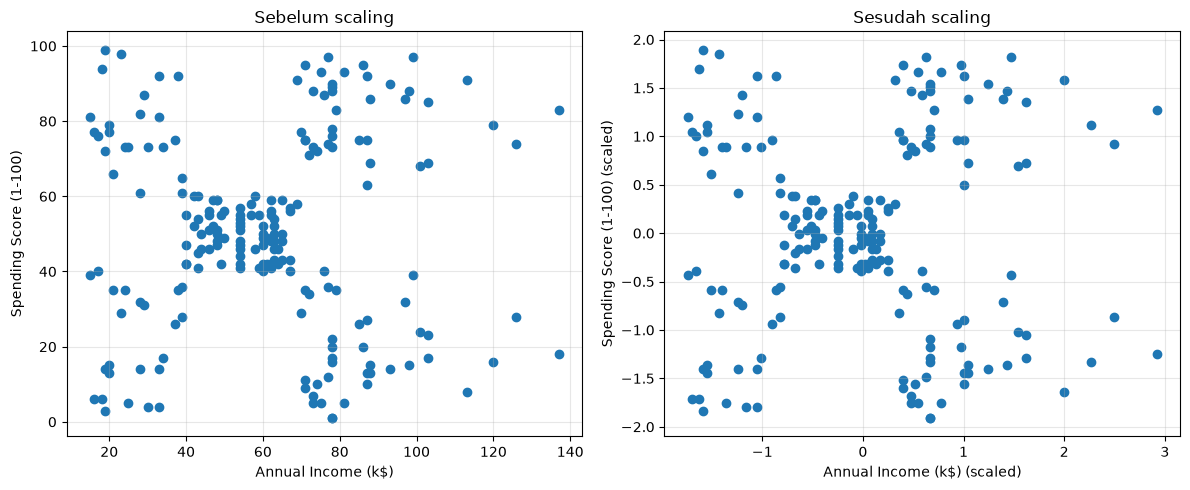

In [20]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'])
ax[0].set_title('Sebelum scaling')
ax[0].set_xlabel('Annual Income (k$)')
ax[0].set_ylabel('Spending Score (1-100)')
ax[0].grid(True, alpha=0.3)

ax[1].scatter(X_scaled['Annual Income (k$)'], X_scaled['Spending Score (1-100)'])
ax[1].set_title('Sesudah scaling')
ax[1].set_xlabel('Annual Income (k$) (scaled)')
ax[1].set_ylabel('Spending Score (1-100) (scaled)')
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Alasan pemilihan fitur:** Kedua fitur ini numerik dan sama-sama berkaitan dengan perilaku pelanggan, yaitu kemampuan finansial (income) dan seberapa sering mereka belanja (spending score). Dengan dua fitur saja, hasil clustering juga bisa langsung dilihat di scatter plot 2D.

`CustomerID` tidak dipakai karena cuma nomor urut pelanggan dan tidak punya makna apa pun. Kalau ikut dimasukkan, jarak antar titik akan ikut dipengaruhi nomor urut, sehingga pelanggan dengan ID yang berdekatan bisa dianggap mirip padahal belum tentu.

**Soal scaling:** Algoritma yang dipakai di sini bergantung pada jarak (`eps` di DBSCAN, `threshold` di BIRCH), jadi fitur dengan rentang besar bisa mendominasi jarak. Di dataset ini skala kedua fitur sebenarnya sudah mirip (std 26.3 dan 25.8), makanya bentuk scatter plot sebelum dan sesudah scaling hampir sama, yang berubah hanya angka di sumbunya. Tetap saja scaling dipakai supaya `eps` dan `threshold` punya satuan yang jelas (dalam standar deviasi) dan kode ini aman kalau nanti ditambah fitur dengan skala berbeda, misalnya Age.


## 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [21]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

In [22]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

print(pd.Series(labels_dbscan).value_counts().sort_index())
n_cluster = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise = list(labels_dbscan).count(-1)
print('Jumlah cluster:', n_cluster)
print('Jumlah noise:', n_noise)

-1    35
 0    12
 1     5
 2     7
 3    88
 4    30
 5    14
 6     9
Name: count, dtype: int64
Jumlah cluster: 7
Jumlah noise: 35


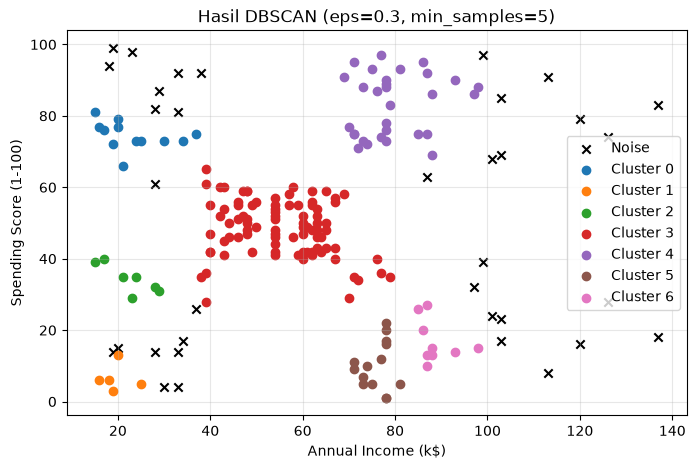

In [23]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

plt.figure(figsize=(8, 5))
for lab in sorted(set(labels_dbscan)):
    mask = labels_dbscan == lab
    if lab == -1:
        plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                    c='black', marker='x', label='Noise')
    else:
        plt.scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'],
                    label='Cluster ' + str(lab))
plt.title('Hasil DBSCAN (eps=0.3, min_samples=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [24]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.

hasil_dbscan = []
for eps in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [3, 5, 8, 10]:
        lbl = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        k = len(set(lbl)) - (1 if -1 in lbl else 0)
        noise = (lbl == -1).sum()
        non_noise = lbl != -1
        if k >= 2:
            sil = silhouette_score(X_scaled[non_noise], lbl[non_noise])
        else:
            sil = np.nan
        hasil_dbscan.append([eps, ms, k, noise, sil])

tabel_dbscan = pd.DataFrame(hasil_dbscan, columns=['eps', 'min_samples', 'jumlah_cluster', 'jumlah_noise', 'silhouette'])
tabel_dbscan.round(3)

,eps,min_samples,jumlah_cluster,jumlah_noise,silhouette
0,0.2,3,13,44,0.470
1,0.2,5,7,77,0.586
2,0.2,8,2,116,0.603
3,0.2,10,1,129,NaN
4,0.3,3,9,14,0.472
5,0.3,5,7,35,0.524
6,0.3,8,5,72,0.593
7,0.3,10,4,88,0.607
8,0.4,3,4,10,0.395
9,0.4,5,4,15,0.478


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Jawaban:**

- **Pengaruh `eps`:** Kalau `eps` dinaikkan, noise berkurang dan jumlah cluster cenderung turun. Pada `min_samples=5`, `eps=0.2` menghasilkan 7 cluster dengan 77 noise, `eps=0.3` menghasilkan 7 cluster dengan 35 noise, `eps=0.4` menjadi 4 cluster dengan 15 noise, `eps=0.5` menjadi 2 cluster dengan 8 noise, dan `eps=0.6` tinggal 1 cluster dengan 5 noise. Jangkauan yang makin besar membuat kelompok yang berdekatan tersambung jadi satu.
- **Pengaruh `min_samples`:** Kebalikannya, makin besar `min_samples`, noise makin banyak karena syarat sebuah titik jadi core point lebih ketat. Pada `eps=0.4`, noise-nya 10 (`min_samples=3`), 15 (5), 25 (8), dan 51 (10). Cluster kecil juga ikut hilang jadi noise.
- **Kombinasi yang kurang bagus:** Semua `eps=0.6` hanya menghasilkan 1 cluster besar. Di sisi lain, `eps=0.2` dengan `min_samples=10` menghasilkan 1 cluster dan 129 noise (lebih dari separuh data), dan `eps=0.2` dengan `min_samples=8` punya 116 noise. Silhouette di baris-baris ini terlihat tinggi (sekitar 0.60) tapi menyesatkan, karena dihitung hanya dari titik yang tersisa setelah noise dibuang.
- **Yang dipilih:** `eps=0.4` dan `min_samples=8` (5 cluster, 25 noise, silhouette 0.549), karena jumlah clusternya sesuai dengan pola di scatter plot dan noise-nya masih 12.5% dari data.


## 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [25]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch.fit_predict(X_scaled)

In [26]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.

print(pd.Series(labels_birch).value_counts().sort_index())
print('Jumlah cluster:', len(set(labels_birch)))

0     36
1    109
2      8
3     25
4     22
Name: count, dtype: int64
Jumlah cluster: 5


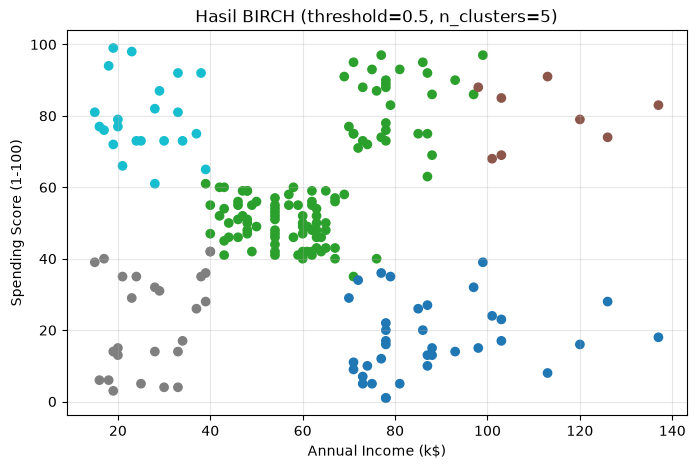

In [27]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

plt.figure(figsize=(8, 5))
plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=labels_birch, cmap='tab10')
plt.title('Hasil BIRCH (threshold=0.5, n_clusters=5)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, alpha=0.3)
plt.show()

In [28]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.

import warnings
warnings.filterwarnings('ignore')

hasil_birch = []
for t in [0.3, 0.5, 0.7, 1.0]:
    b5 = Birch(threshold=t, n_clusters=5).fit(X_scaled)
    b_none = Birch(threshold=t, n_clusters=None).fit(X_scaled)
    lbl = b5.labels_
    if len(set(lbl)) >= 2:
        sil = silhouette_score(X_scaled, lbl)
    else:
        sil = np.nan
    hasil_birch.append([t, len(b5.subcluster_centers_), len(set(lbl)), sil, len(set(b_none.labels_))])

tabel_birch = pd.DataFrame(hasil_birch, columns=['threshold', 'jumlah_subcluster', 'jumlah_cluster (n_clusters=5)', 'silhouette', 'jumlah_cluster (n_clusters=None)'])
tabel_birch.round(3)

,threshold,jumlah_subcluster,jumlah_cluster (n_clusters=5),silhouette,jumlah_cluster (n_clusters=None)
0,0.3,23,5,0.478,23
1,0.5,10,5,0.414,10
2,0.7,6,5,0.421,6
3,1.0,4,4,0.389,4


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Jawaban:**

- **Pengaruh `threshold`:** Makin besar `threshold`, jumlah subcluster makin sedikit, yaitu 23 (0.3), 10 (0.5), 6 (0.7), dan 4 (1.0). Kalau `n_clusters=None`, jumlah cluster akhir sama dengan jumlah subcluster itu. Kalau `n_clusters=5`, hasilnya tetap 5 cluster sampai `threshold=0.7`, tetapi di `threshold=1.0` cuma terbentuk 4 karena subcluster-nya sendiri hanya ada 4. Silhouette tertinggi ada di `threshold=0.3` (0.478), lalu 0.421 (0.7), 0.414 (0.5), dan 0.389 (1.0).
- **BIRCH vs DBSCAN untuk titik yang jauh:** DBSCAN menandai titik jauh sebagai noise (-1), sedangkan BIRCH tetap memasukkan setiap titik ke salah satu cluster. Contohnya pada `threshold=0.3` dan `n_clusters=5`, tiga pelanggan dengan income sekitar 120 sampai 137 k$ dikelompokkan jadi cluster kecil sendiri (3 anggota). Di DBSCAN titik-titik seperti ini masuk ke noise.
- **Pengaruh `n_clusters`:** Ya, hasilnya berubah. Dengan `n_clusters=None` pada `threshold=0.3` terbentuk 23 cluster yang terlalu banyak untuk diinterpretasikan. Dengan `n_clusters=5`, subcluster tadi digabung lagi menjadi 5 cluster yang lebih mudah dibaca.


## 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [29]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)

In [30]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

print(pd.Series(labels_gmm).value_counts().sort_index())
proba = gmm.predict_proba(X_scaled)
proba_df = pd.DataFrame(proba, columns=['C0', 'C1', 'C2', 'C3', 'C4'])
print(proba_df.head(10).round(3))

# titik yang probabilitas maksimumnya di bawah 0.9
max_proba = proba.max(axis=1)
print('Jumlah titik dengan prob. maksimum < 0.9:', (max_proba < 0.9).sum())
print('Prob. maksimum terkecil:', round(max_proba.min(), 3))
proba_df[max_proba < 0.9].round(3)

0    84
1    39
2    21
3    33
4    23
Name: count, dtype: int64
      C0   C1     C2   C3     C4
0  0.000  0.0  0.001  0.0  0.999
1  0.000  0.0  1.000  0.0  0.000
2  0.000  0.0  0.000  0.0  1.000
3  0.000  0.0  1.000  0.0  0.000
4  0.000  0.0  0.002  0.0  0.998
5  0.000  0.0  1.000  0.0  0.000
6  0.000  0.0  0.000  0.0  1.000
7  0.000  0.0  1.000  0.0  0.000
8  0.000  0.0  0.000  0.0  1.000
9  0.001  0.0  0.998  0.0  0.000
Jumlah titik dengan prob. maksimum < 0.9: 8
Prob. maksimum terkecil: 0.503


,C0,C1,C2,C3,C4
27,0.279,0.000,0.675,0.000,0.046
45,0.822,0.007,0.157,0.000,0.014
47,0.891,0.000,0.001,0.000,0.108
48,0.611,0.000,0.000,0.000,0.388
49,0.611,0.000,0.000,0.000,0.388
55,0.796,0.000,0.000,0.000,0.204
124,0.497,0.000,0.000,0.503,0.000
160,0.772,0.000,0.000,0.228,0.000


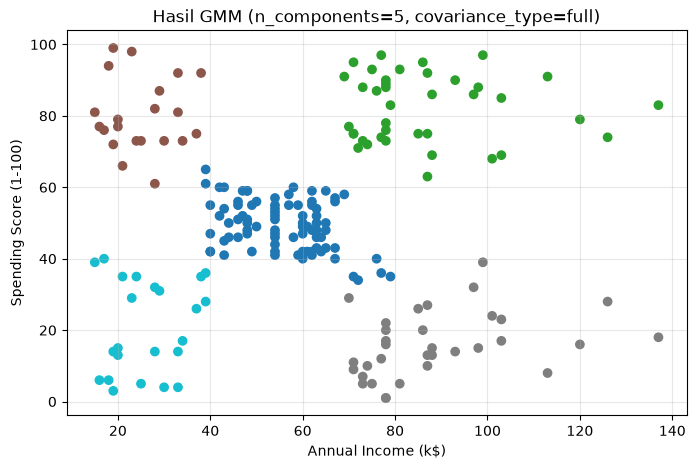

In [31]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

plt.figure(figsize=(8, 5))
plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=labels_gmm, cmap='tab10')
plt.title('Hasil GMM (n_components=5, covariance_type=full)')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, alpha=0.3)
plt.show()

In [32]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

hasil_gmm = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type='full', random_state=42).fit(X_scaled)
    lbl = g.predict(X_scaled)
    hasil_gmm.append([k, silhouette_score(X_scaled, lbl), g.bic(X_scaled)])

tabel_gmm = pd.DataFrame(hasil_gmm, columns=['n_components', 'silhouette', 'BIC'])
tabel_gmm.round(3)

,n_components,silhouette,BIC
0,2,0.379,1153.905
1,3,0.430,1151.718
2,4,0.413,1103.790
3,5,0.554,1058.652
4,6,0.517,1074.683
5,7,0.509,1087.329
6,8,0.430,1102.371


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Jawaban:**

- **Arti probabilitas keanggotaan:** Nilainya adalah peluang sebuah titik berasal dari tiap komponen Gaussian, dan jumlahnya per baris adalah 1. Kebanyakan titik hampir pasti masuk ke satu komponen (misalnya 0.998 sampai 1.000 pada 10 baris pertama). Ada 8 titik dengan probabilitas maksimum di bawah 0.9, dan yang paling tidak pasti adalah baris 124 dengan peluang 0.503 dan 0.497 untuk dua komponen. Titik-titik seperti ini biasanya ada di perbatasan antar cluster.
- **Pengaruh `n_components`:** Pada `n_components=2` dan 3, silhouette-nya rendah (0.379 dan 0.430) dan BIC-nya tinggi (1153.9 dan 1151.7), jadi belum cukup menangkap kelompok yang ada. Pada 5 komponen silhouette naik ke 0.554 dan BIC turun ke 1058.7. Setelah itu silhouette turun lagi (0.517 untuk 6, 0.509 untuk 7) dan BIC naik lagi (1074.7 dan 1087.3).
- **Kenapa jumlah cluster harus ditentukan dulu:** GMM adalah model parametrik. Jumlah komponen menentukan berapa set parameter (mean, kovarians, bobot) yang diestimasi oleh EM, jadi angkanya harus ada sebelum model dilatih. Untuk memilihnya biasanya dicoba beberapa nilai lalu dibandingkan dengan BIC seperti di tabel di atas.
- **Silhouette tertinggi vs BIC terendah:** Keduanya sama-sama jatuh di `n_components=5`.


## 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [33]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluasi(data, labels, buang_noise=False):
    data = np.array(data)
    labels = np.array(labels)
    if buang_noise:
        mask = labels != -1
        data = data[mask]
        labels = labels[mask]
    k = len(set(labels))
    if k < 2 or k >= len(data):
        return np.nan, np.nan, np.nan
    sil = silhouette_score(data, labels)
    dbi = davies_bouldin_score(data, labels)
    chs = calinski_harabasz_score(data, labels)
    return sil, dbi, chs

In [34]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

# parameter terbaik dari tabel-tabel sebelumnya
labels_dbscan_best = DBSCAN(eps=0.4, min_samples=8).fit_predict(X_scaled)
labels_birch_best = Birch(threshold=0.3, n_clusters=5).fit_predict(X_scaled)
labels_gmm_best = labels_gmm

hasil_akhir = []
for nama, lbl, buang in [('DBSCAN', labels_dbscan_best, True),
                         ('BIRCH', labels_birch_best, False),
                         ('GMM', labels_gmm_best, False)]:
    k = len(set(lbl)) - (1 if -1 in lbl else 0)
    noise = (lbl == -1).sum()
    sil, dbi, chs = evaluasi(X_scaled, lbl, buang)
    hasil_akhir.append([nama, k, noise, sil, dbi, chs])

tabel_akhir = pd.DataFrame(hasil_akhir, columns=['model', 'jumlah_cluster', 'jumlah_noise', 'silhouette', 'davies_bouldin', 'calinski_harabasz'])
tabel_akhir.round(3)

,model,jumlah_cluster,jumlah_noise,silhouette,davies_bouldin,calinski_harabasz
0,DBSCAN,5,25,0.549,0.501,222.065
1,BIRCH,5,0,0.478,0.648,144.013
2,GMM,5,0,0.554,0.576,244.940


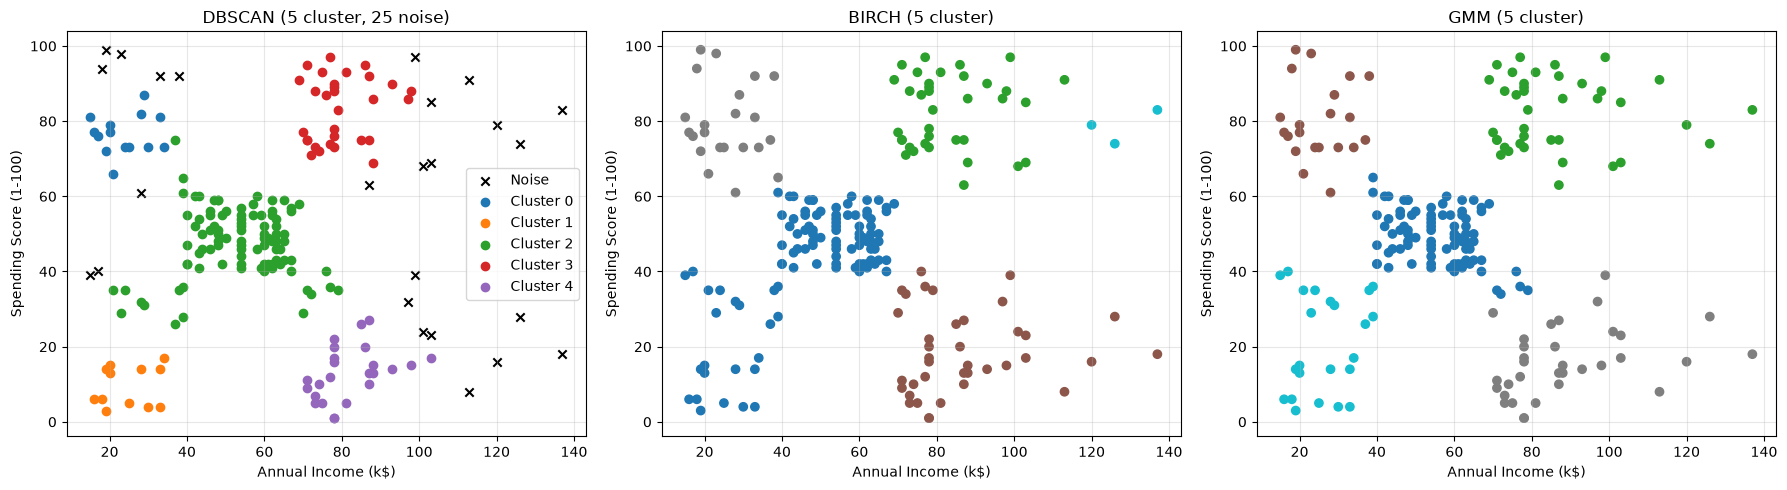

In [35]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

fig, ax = plt.subplots(1, 3, figsize=(18, 5))

for lab in sorted(set(labels_dbscan_best)):
    mask = labels_dbscan_best == lab
    if lab == -1:
        ax[0].scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], c='black', marker='x', label='Noise')
    else:
        ax[0].scatter(X.loc[mask, 'Annual Income (k$)'], X.loc[mask, 'Spending Score (1-100)'], label='Cluster ' + str(lab))
ax[0].set_title('DBSCAN (5 cluster, 25 noise)')
ax[0].legend()

ax[1].scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=labels_birch_best, cmap='tab10')
ax[1].set_title('BIRCH (5 cluster)')

ax[2].scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=labels_gmm_best, cmap='tab10')
ax[2].set_title('GMM (5 cluster)')

for a in ax:
    a.set_xlabel('Annual Income (k$)')
    a.set_ylabel('Spending Score (1-100)')
    a.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [36]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

for nama, lbl in [('DBSCAN', labels_dbscan_best), ('BIRCH', labels_birch_best), ('GMM', labels_gmm_best)]:
    tmp = X.copy()
    tmp['cluster'] = lbl
    profil = tmp.groupby('cluster').agg(
        jumlah=('Annual Income (k$)', 'count'),
        median_income=('Annual Income (k$)', 'median'),
        mean_income=('Annual Income (k$)', 'mean'),
        median_spending=('Spending Score (1-100)', 'median'),
        mean_spending=('Spending Score (1-100)', 'mean')
    )
    print(nama)
    print(profil.round(1))
    print()

DBSCAN
         jumlah  median_income  mean_income  median_spending  mean_spending
cluster                                                                    
-1           25          101.0         83.0             68.0           60.5
 0           14           22.5         23.6             76.5           76.4
 1           12           22.5         24.6              9.5            9.6
 2           95           54.0         53.3             48.0           47.8
 3           30           78.0         79.5             86.0           83.1
 4           24           78.0         81.9             13.0           13.0

BIRCH
         jumlah  median_income  mean_income  median_spending  mean_spending
cluster                                                                    
0           101           50.0         48.2             47.0           43.4
1            36           78.0         83.1             85.5           82.4
2            38           80.0         87.0             16.5           18.

### Ringkasan Perbandingan

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak, jumlah cluster muncul dari `eps` dan `min_samples` | Tergantung. Kalau `n_clusters` diisi ya, kalau `None` jumlahnya ditentukan `threshold` | Ya, lewat `n_components` |
| Dapat memberi label noise secara eksplisit? | Ya, label -1 | Tidak | Tidak, tetapi probabilitas rendah bisa jadi tanda titik yang ambigu |
| Parameter yang paling memengaruhi hasil | `eps` dan `min_samples` | `threshold` (dan `n_clusters`) | `n_components` dan `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Bentuk bebas, selama kepadatannya cukup | Cenderung bulat dan kompak | Elips (Gaussian), bentuknya tergantung `covariance_type` |
| Kelebihan | Bisa mendeteksi outlier dan tidak mengasumsikan bentuk cluster | Cepat dan hemat memori, cocok untuk data besar | Ada probabilitas keanggotaan, dan BIC bisa membantu memilih jumlah komponen |
| Kekurangan | Sensitif terhadap `eps` dan `min_samples`, sebagian pelanggan jadi noise | Hasil bergantung `threshold`. Di data ini kelompok income rendah dan spending rendah menyatu dengan gerombol tengah | Mengasumsikan data berdistribusi Gaussian dan jumlah komponen harus dicoba-coba |


## 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

**Jawaban:**

1. Algoritma yang dipakai berbasis jarak, jadi fitur dengan rentang yang besar bisa mendominasi perhitungan. Di dataset ini sebenarnya skala income dan spending score sudah mirip (std 26.3 dan 25.8), sehingga bentuk scatter plot tidak banyak berubah setelah scaling. Scaling tetap dilakukan supaya `eps` dan `threshold` dibaca dalam satuan standar deviasi, dan hasil ini tidak bergantung pada satuan fitur kalau nanti ada fitur tambahan.
2. Kenaikan `eps` mengurangi noise dan menggabungkan cluster yang berdekatan (sampai jadi 1 cluster di `eps=0.6`). Kenaikan `min_samples` menambah noise, misalnya di `eps=0.4` noise naik dari 10 ke 51 saat `min_samples` naik dari 3 ke 10.
3. `threshold` yang lebih besar menghasilkan subcluster yang lebih sedikit (23, 10, 6, 4 untuk 0.3, 0.5, 0.7, 1.0). `n_clusters` kemudian menggabungkan subcluster itu jadi jumlah cluster akhir yang diinginkan. Tanpa `n_clusters`, cluster akhir sama dengan subcluster.
4. Probabilitas keanggotaan GMM adalah peluang sebuah titik berasal dari tiap komponen. EM bekerja bolak-balik: pada E-step dihitung probabilitas tiap titik terhadap tiap komponen dengan parameter yang ada, lalu pada M-step mean, kovarians, dan bobot komponen diperbarui dengan probabilitas itu sebagai bobot. Langkah ini diulang sampai konvergen. Di output, sebagian besar titik punya probabilitas di atas 0.99 pada satu komponen, dan hanya 8 titik yang maksimumnya di bawah 0.9.
5. GMM dengan 5 komponen menurut saya paling mudah diinterpretasikan. Semua pelanggan masuk ke salah satu dari 5 segmen yang profilnya jelas, dan ada probabilitas yang menunjukkan seberapa yakin sebuah titik masuk ke segmennya. DBSCAN hasilnya hampir sama jelasnya, tetapi 25 pelanggan (12.5%) jadi noise sehingga tidak punya segmen. BIRCH paling sulit dibaca karena ada cluster yang cuma beranggotakan 3 pelanggan.
6. Tidak sepenuhnya sama. Silhouette tertinggi dimiliki GMM (0.554), tipis di atas DBSCAN (0.549). Davies-Bouldin terendah dimiliki DBSCAN (0.501), sedangkan Calinski-Harabasz tertinggi dimiliki GMM (244.94). BIRCH paling rendah di ketiga metrik. Salah satu penyebabnya, metrik DBSCAN dihitung tanpa 25 titik noise, sehingga cluster yang tersisa terlihat lebih rapat dan terpisah, jadi perbandingannya tidak benar-benar setara. Selain itu masing-masing metrik punya kecenderungan sendiri, misalnya silhouette dan Calinski-Harabasz menyukai cluster yang bulat dan padat.
7. Karakteristik cluster GMM berdasarkan median:
   - Cluster 0 (84 pelanggan): income 55.5 k$, spending 49.5. Pelanggan menengah, bisa dinamai "Pelanggan Menengah".
   - Cluster 1 (39 pelanggan): income 79 k$, spending 83. Pendapatan tinggi dan belanja tinggi, bisa dinamai "Pelanggan Premium".
   - Cluster 2 (21 pelanggan): income 24 k$, spending 77. Pendapatan rendah tapi belanja tinggi, bisa dinamai "Penghasilan Rendah, Gemar Belanja".
   - Cluster 3 (33 pelanggan): income 86 k$, spending 15. Pendapatan tinggi tapi belanja rendah, bisa dinamai "Penghasilan Tinggi, Hemat Belanja".
   - Cluster 4 (23 pelanggan): income 25 k$, spending 17. Pendapatan rendah dan belanja rendah, bisa dinamai "Pelanggan Hemat".
8. Dengan dua fitur saja, informasi seperti umur dan gender tidak ikut dipertimbangkan, jadi dua pelanggan yang income dan spending-nya sama dianggap mirip walaupun profilnya berbeda. Datanya juga cuma 200 baris, sehingga cluster kecil (3 anggota di BIRCH, 12 sampai 14 anggota di DBSCAN) gampang berubah kalau parameter digeser sedikit. Hasilnya belum tentu berlaku untuk pelanggan mall secara umum.


## 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

**Kesimpulan:**

- **Algoritma paling berguna:** GMM dengan 5 komponen. Silhouette-nya tertinggi (0.554), Calinski-Harabasz-nya tertinggi (244.94), BIC-nya terendah di `n_components=5`, dan semua pelanggan mendapat segmen. Hasilnya juga cocok dengan 5 kelompok yang sudah terlihat di scatter plot awal.
- **Parameter yang dipilih:** DBSCAN memakai `eps=0.4` dan `min_samples=8` (5 cluster, 25 noise), karena `eps=0.6` menjadi 1 cluster sedangkan `eps=0.2` membuang terlalu banyak titik. BIRCH memakai `threshold=0.3` dan `n_clusters=5`, karena silhouette-nya tertinggi (0.478) di antara threshold yang dicoba. GMM memakai `n_components=5`, `covariance_type='full'`, dan `random_state=42`, karena silhouette dan BIC sama-sama menunjuk ke angka 5.
- **Perbedaan utama:** DBSCAN membentuk cluster dari kepadatan dan menyisihkan titik yang jauh sebagai noise. BIRCH merangkum data lewat subcluster dan selalu memasukkan semua titik ke cluster, sehingga titik yang jauh malah bisa membentuk cluster kecil sendiri. GMM memodelkan data sebagai campuran distribusi Gaussian dan memberi probabilitas keanggotaan, jadi titik di perbatasan kelihatan ambigunya.
- **Eksperimen lanjutan:** menambahkan `Age` sebagai fitur ketiga (dan memakai `Gender` untuk interpretasi), mencoba `covariance_type` lain (`tied`, `diag`, `spherical`) dengan BIC sebagai pembanding, memakai k-distance plot untuk menentukan `eps` DBSCAN, dan mencoba `n_clusters` BIRCH selain 5.


#### Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)